<a href="https://colab.research.google.com/github/AlbertPuentes/App_Deep-Learning_AVANCE_PROY_III/blob/main/R2_A2_S10_AVANCE_PROY_III.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

✅ Ejecución completa. Gráficos guardados en 'evaluacion_modelo_visual.png'.


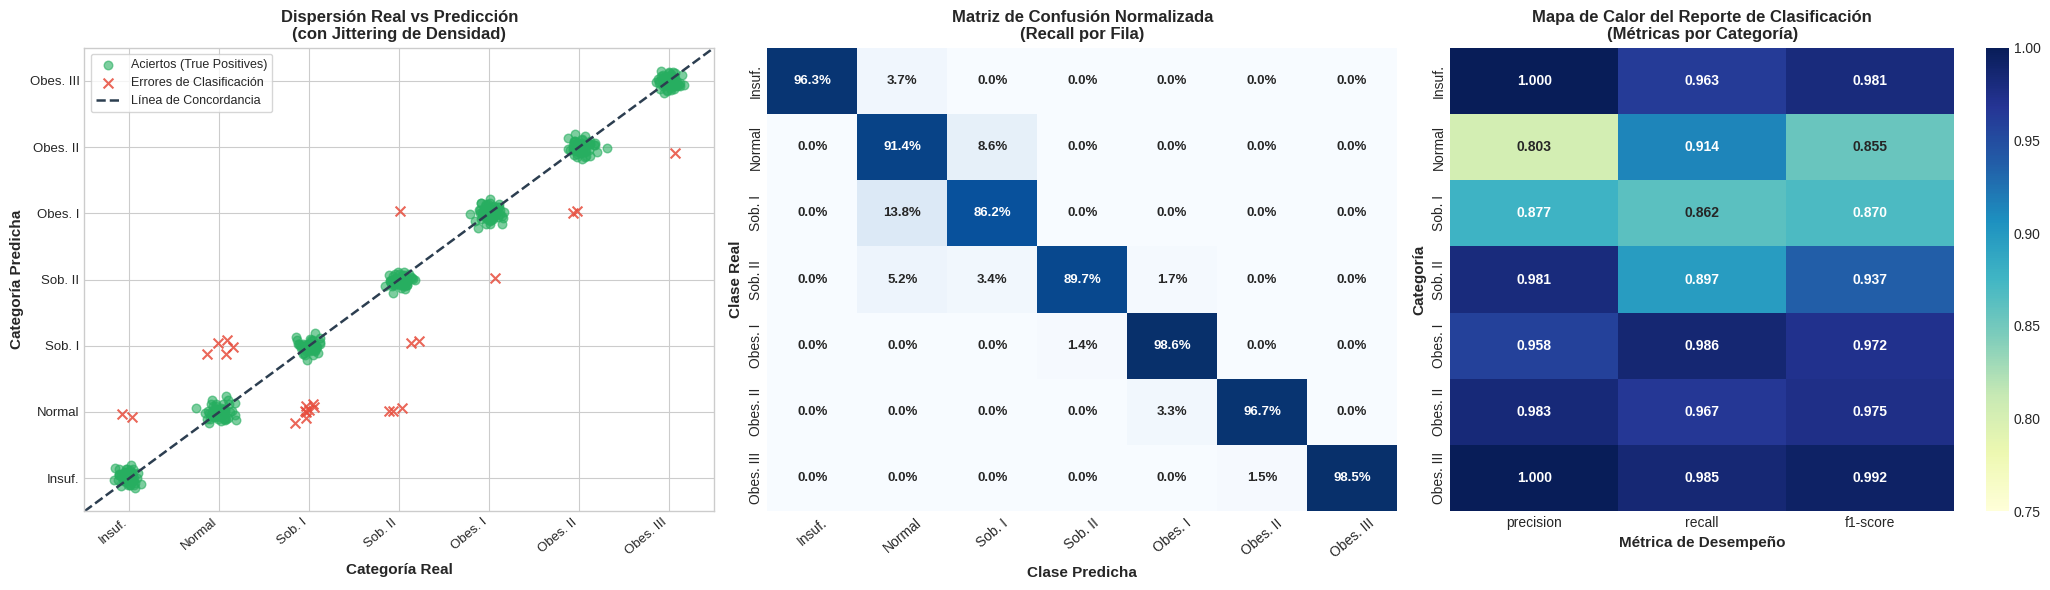

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import classification_report, accuracy_score, balanced_accuracy_score, confusion_matrix
import joblib
import warnings
warnings.filterwarnings('ignore')

# 1. Carga de datos y Protocolo Split-First
filepath = 'ObesityDataSet_raw_and_data_sinthetic.csv'
df = pd.read_csv(filepath)
X = df.drop(columns=['NObeyesdad'])
y = df['NObeyesdad']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# 2. Pipeline AIDPCP
class FeatureEngineer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None): return self
    def transform(self, X):
        X_new = X.copy()
        if 'Weight' in X_new.columns and 'Height' in X_new.columns:
            X_new['IMC'] = X_new['Weight'] / (X_new['Height'] ** 2)
        return X_new

numeric_features = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE', 'IMC']
categorical_features = ['Gender', 'family_history_with_overweight', 'FAVC', 'SMOKE', 'SCC', 'MTRANS', 'CAEC', 'CALC']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline(steps=[('scaler', StandardScaler())]), numeric_features),
        ('cat', Pipeline(steps=[('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical_features)
    ], remainder='drop')

pipeline = Pipeline(steps=[('feature_engineering', FeatureEngineer()), ('preprocessor', preprocessor)])
X_train_prep = pipeline.fit_transform(X_train)
X_test_prep = pipeline.transform(X_test)
joblib.dump(pipeline, 'aidpcp_pipeline_final.joblib')

# 3. Balanceo de clases (Custom RUS)
def custom_random_undersampling(X, y, random_state=42):
    np.random.seed(random_state)
    df_temp = pd.DataFrame(X)
    df_temp['target'] = y.values
    min_class_size = df_temp['target'].value_counts().min()
    resampled_df = pd.concat([class_df.sample(min_class_size, random_state=random_state) for _, class_df in df_temp.groupby('target')])
    return resampled_df.drop(columns=['target']).values, resampled_df['target'].values

X_train_resampled, y_train_resampled = custom_random_undersampling(X_train_prep, y_train)

# 4. Entrenamiento del modelo ETC optimizado
best_model = ExtraTreesClassifier(n_estimators=300, min_samples_split=5, max_depth=15, random_state=42, n_jobs=-1)
best_model.fit(X_train_resampled, y_train_resampled)
joblib.dump(best_model, 'etc_model_production.joblib')

# 5. Predicción en Test Hold-out
y_pred = best_model.predict(X_test_prep)

# 6. Generación de Visualizaciones Diagnósticas
class_order = [
    'Insufficient_Weight',
    'Normal_Weight',
    'Overweight_Level_I',
    'Overweight_Level_II',
    'Obesity_Type_I',
    'Obesity_Type_II',
    'Obesity_Type_III'
]
short_labels = ['Insuf.', 'Normal', 'Sob. I', 'Sob. II', 'Obes. I', 'Obes. II', 'Obes. III']

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# A. Gráfico de Dispersión Real vs Predicción
label_to_idx = {cls: i for i, cls in enumerate(class_order)}
y_test_num = np.array([label_to_idx[val] for val in y_test])
y_pred_num = np.array([label_to_idx[val] for val in y_pred])

np.random.seed(42)
jitter_x = y_test_num + np.random.normal(0, 0.08, size=len(y_test_num))
jitter_y = y_pred_num + np.random.normal(0, 0.08, size=len(y_pred_num))

correct_mask = (y_test_num == y_pred_num)
axes[0].scatter(jitter_x[correct_mask], jitter_y[correct_mask], color='#27ae60', alpha=0.6, label='Aciertos (True Positives)', s=38)
axes[0].scatter(jitter_x[~correct_mask], jitter_y[~correct_mask], color='#e74c3c', alpha=0.85, label='Errores de Clasificación', s=50, marker='x')
axes[0].plot([-0.5, 6.5], [-0.5, 6.5], color='#2c3e50', linestyle='--', linewidth=1.8, label='Línea de Concordancia')

axes[0].set_xticks(range(len(class_order)))
axes[0].set_yticks(range(len(class_order)))
axes[0].set_xticklabels(short_labels, rotation=40, ha='right', fontsize=9.5)
axes[0].set_yticklabels(short_labels, fontsize=9.5)
axes[0].set_xlabel('Categoría Real', fontweight='bold', fontsize=11)
axes[0].set_ylabel('Categoría Predicha', fontweight='bold', fontsize=11)
axes[0].set_title('Dispersión Real vs Predicción\n(con Jittering de Densidad)', fontsize=12, fontweight='bold')
axes[0].legend(loc='upper left', frameon=True, fontsize=9)
axes[0].set_xlim(-0.5, 6.5)
axes[0].set_ylim(-0.5, 6.5)

# B. Matriz de Confusión Normalizada
cm = confusion_matrix(y_test, y_pred, labels=class_order)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

sns.heatmap(cm_norm, annot=True, fmt='.1%', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=short_labels, yticklabels=short_labels, annot_kws={"size": 9.5, "fontweight": "bold"})
axes[1].set_title('Matriz de Confusión Normalizada\n(Recall por Fila)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Clase Predicha', fontweight='bold', fontsize=11)
axes[1].set_ylabel('Clase Real', fontweight='bold', fontsize=11)
axes[1].tick_params(axis='x', rotation=40)

# C. Mapa de Calor del Reporte de Clasificación
report_dict = classification_report(y_test, y_pred, labels=class_order, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
report_classes = report_df.loc[class_order, ['precision', 'recall', 'f1-score']]
report_classes.index = short_labels

sns.heatmap(report_classes, annot=True, fmt='.3f', cmap='YlGnBu', cbar=True, ax=axes[2],
            annot_kws={"size": 10, "fontweight": "bold"}, vmin=0.75, vmax=1.0)
axes[2].set_title('Mapa de Calor del Reporte de Clasificación\n(Métricas por Categoría)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Métrica de Desempeño', fontweight='bold', fontsize=11)
axes[2].set_ylabel('Categoría', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.savefig('evaluacion_modelo_visual.png', dpi=300, bbox_inches='tight')
print("✅ Ejecución completa. Gráficos guardados en 'evaluacion_modelo_visual.png'.")